# Human Activity Recognition (HAR)
## Modelado y Clasificación Exclusivo: Random Forest

> **Nota de Colaboración de Equipo:**  
> Este notebook está destinado **única y exclusivamente al entrenamiento, optimización de hiperparámetros y evaluación del clasificador Random Forest**. Como parte de la estrategia del equipo para comparar diversos algoritmos (SVM, KNN, Redes Neuronales, etc.), este flujo garantiza reproducibilidad mediante la misma partición estratificada 80/20 y escalamiento estándar de características.

---

### Objetivos del Notebook:
1. **Carga y verificación del dataset procesado:** Cargar `data/processed/dataset_har_features.csv`, validar integridad (0 nulos, 0 infinitos) y consistencia de las 5 actividades (`caminar`, `correr`, `escaleras`, `sentado`, `vehiculo`).
2. **Separación de variables ($X, y$):** Extraer las 24 características estadísticas descartando metadatos (`subject`, `trial`, `window_id`) para prevenir fuga de datos (*data leakage*).
3. **División estratificada (80% / 20%):** Particionar en conjuntos de Entrenamiento (80%) y Prueba (20%) mediante `train_test_split(..., stratify=y)` para preservar la proporción real de cada actividad.
4. **Escalamiento de características (`StandardScaler`):** Ajustar el escalador exclusivamente en `X_train` (`fit_transform`) y aplicarlo en `X_test` (`transform`).
5. **Entrenamiento y ajuste de hiperparámetros (`GridSearchCV`):** Optimizar hiperparámetros clave (`n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`) con validación cruzada estratificada de 5 folds.
6. **Evaluación completa en el conjunto de prueba:** Calcular métricas globales (Accuracy, F1-macro), matriz de confusión y reporte de clasificación por actividad.
7. **Importancia de características (*Feature Importance*):** Identificar qué variables biomecánicas fueron más determinantes para el bosque.
8. **Exportación del modelo:** Guardar el modelo entrenado y optimizado en la carpeta `models/random_forest_model.pkl` en formato `.pkl` usando `joblib`.

In [1]:
import os
from pathlib import Path
import time
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import joblib

# Asegurar ejecución desde la raíz del proyecto
if Path.cwd().name == 'notebooks':
    os.chdir('..')

print(f"Directorio de trabajo actual: {os.getcwd()}")

# Estilo gráfico consistente
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

# Constantes del pipeline
DATA_PATH = Path("data/processed/dataset_har_features.csv")
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20

print("Parámetros configurados:")
print(f" - Dataset objetivo: {DATA_PATH}")
print(f" - Carpeta de modelos: {MODELS_DIR}")
print(f" - Proporción de prueba (test_size): {TEST_SIZE * 100:.0f}% (Entrenamiento: {(1 - TEST_SIZE) * 100:.0f}%)")
print(f" - Semilla aleatoria (random_state): {RANDOM_STATE}")

Directorio de trabajo actual: /home/alittoss/Programacion/DataScience/Tratamiento/Human-Activity-Recognition
Parámetros configurados:
 - Dataset objetivo: data/processed/dataset_har_features.csv
 - Carpeta de modelos: models
 - Proporción de prueba (test_size): 20% (Entrenamiento: 80%)
 - Semilla aleatoria (random_state): 42


## 1. Carga del Dataset Procesado y Separación de Variables ($X, y$)

Cargamos `data/processed/dataset_har_features.csv` y validamos que no existan valores nulos o infinitos.

### Prevención de Fuga de Datos (*Data Leakage*):
El dataset incluye columnas de metadatos (`subject`, `trial`, `window_id`) útiles para trazabilidad durante la adquisición y segmentación, pero **no deben ingresar como predictores** al modelo:
- `subject`: El modelo debe generalizar sobre la cinemática de la actividad independientemente de la persona.
- `trial` y `window_id`: Son índices secuenciales/temporales sin relevancia física.

Por lo tanto, la matriz $X$ contendrá exclusivamente las **24 características estadísticas** de aceleración y el vector $y$ la columna `activity`.

Dimensiones del dataset cargado: 7490 ventanas x 28 columnas

Validación de datos exitosa (0 nulos, 0 infinitos, 5 clases únicas).
 - Matriz de características X: (7490, 24)
 - Vector objetivo y: (7490,)
 - Sujetos incluidos: ['alex', 'arturo', 'bere', 'juan', 'leo']


,Ventanas (N),Proporción (%)
activity,,
sentado,1903,25.41
vehiculo,1548,20.67
escaleras,1356,18.10
correr,1352,18.05
caminar,1331,17.77


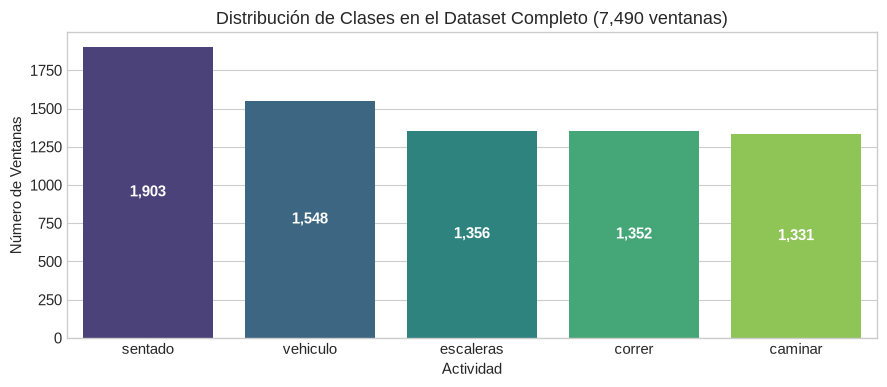

In [2]:
# 1. Cargar el dataset procesado
df = pd.read_csv(DATA_PATH)
print(f"Dimensiones del dataset cargado: {df.shape[0]} ventanas x {df.shape[1]} columnas")

# Normalizar etiquetas de actividad (quitar acentos, espacios y uniformar a minúsculas)
def normalizar_etiqueta(texto):
    texto = str(texto).strip().lower()
    return ''.join(c for c in unicodedata.normalize('NFKD', texto) if not unicodedata.combining(c))

df['activity'] = df['activity'].apply(normalizar_etiqueta)

# 2. Definir columnas de metadatos, objetivo y predictores
TARGET_COL = 'activity'
META_COLS = ['activity', 'subject', 'trial', 'window_id']
FEATURE_COLS = [col for col in df.columns if col not in META_COLS]

# 3. Verificaciones de integridad
null_count = df[FEATURE_COLS + [TARGET_COL]].isnull().sum().sum()
inf_count = np.isinf(df[FEATURE_COLS].to_numpy()).sum()

assert null_count == 0, f"Se encontraron {null_count} valores nulos."
assert inf_count == 0, f"Se encontraron {inf_count} valores infinitos."
assert len(FEATURE_COLS) == 24, f"Se esperaban 24 características, se encontraron {len(FEATURE_COLS)}."
assert df[TARGET_COL].nunique() == 5, f"Se esperaban 5 actividades únicas, se encontraron: {df[TARGET_COL].unique()}"

# 4. Separar matriz de características (X) y vector objetivo (y)
X = df[FEATURE_COLS].copy()
y = df[TARGET_COL].copy()

print(f"\nValidación de datos exitosa (0 nulos, 0 infinitos, 5 clases únicas).")
print(f" - Matriz de características X: {X.shape}")
print(f" - Vector objetivo y: {y.shape}")
print(f" - Sujetos incluidos: {sorted(df['subject'].unique())}")

# Distribución inicial de clases
class_dist = y.value_counts()
class_dist_pct = y.value_counts(normalize=True) * 100
dist_summary = pd.DataFrame({
    'Ventanas (N)': class_dist,
    'Proporción (%)': class_dist_pct.round(2)
})
display(dist_summary)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=class_dist.index, y=class_dist.values, palette='viridis', ax=ax)
ax.set_title("Distribución de Clases en el Dataset Completo (7,490 ventanas)")
ax.set_xlabel("Actividad")
ax.set_ylabel("Número de Ventanas")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()

## 2. División de Datos en Entrenamiento (80%) y Prueba (20%) con Estratificación

Para evaluar objetivamente la capacidad de generalización del clasificador Random Forest, dividimos el dataset en dos subconjuntos disjuntos:
- **Conjunto de Entrenamiento (`80%`, ~5,992 muestras):** Para ajustar el escalador y entrenar el modelo mediante búsqueda de hiperparámetros con validación cruzada.
- **Conjunto de Prueba (`20%`, ~1,498 muestras):** Reservado estrictamente para la evaluación final no sesgada.

### Estratificación (`stratify=y`):
Dado que la actividad `sentado` tiene mayor frecuencia relativa respecto a otras clases, es imprescindible utilizar el parámetro `stratify=y` para que la proporción porcentual de cada actividad se mantenga exactamente idéntica tanto en entrenamiento como en prueba.

Dimensiones resultantes de la partición:
 - X_train: (5992, 24) | y_train: (5992,)
 - X_test:  (1498, 24)  | y_test:  (1498,)

Validación de estratificación superada (diferencia máxima entre Train y Test: 0.04%).


,Original (N),Original (%),Train (N),Train (%),Test (N),Test (%)
activity,,,,,,
sentado,1903,25.41,1522,25.40,381,25.43
vehiculo,1548,20.67,1238,20.66,310,20.69
escaleras,1356,18.10,1085,18.11,271,18.09
correr,1352,18.05,1082,18.06,270,18.02
caminar,1331,17.77,1065,17.77,266,17.76


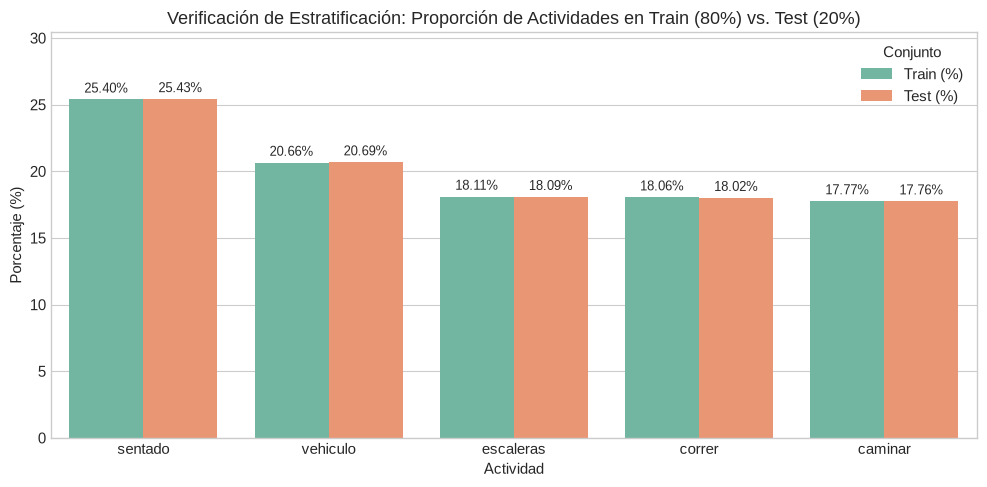

In [3]:
# División estratificada 80% entrenamiento / 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Dimensiones resultantes de la partición:")
print(f" - X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f" - X_test:  {X_test.shape}  | y_test:  {y_test.shape}")

# Validación formal de la estratificación
train_pct = y_train.value_counts(normalize=True) * 100
test_pct = y_test.value_counts(normalize=True) * 100
orig_pct = y.value_counts(normalize=True) * 100

prop_comparison = pd.DataFrame({
    'Original (N)': y.value_counts(),
    'Original (%)': orig_pct.round(2),
    'Train (N)': y_train.value_counts(),
    'Train (%)': train_pct.round(2),
    'Test (N)': y_test.value_counts(),
    'Test (%)': test_pct.round(2)
})
display(prop_comparison)

# Verificar que la diferencia máxima de proporción sea despreciable (< 0.2%)
max_diff = (prop_comparison['Train (%)'] - prop_comparison['Test (%)']).abs().max()
assert max_diff < 0.2, f"Desviación excesiva en la estratificación: {max_diff:.2f}%"
print(f"\nValidación de estratificación superada (diferencia máxima entre Train y Test: {max_diff:.2f}%).")

# Visualización comparativa de proporciones
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = prop_comparison[['Train (%)', 'Test (%)']].reset_index().melt(
    id_vars='activity', var_name='Conjunto', value_name='Porcentaje (%)'
)

sns.barplot(data=plot_df, x='activity', y='Porcentaje (%)', hue='Conjunto', palette='Set2', ax=ax)
ax.set_title("Verificación de Estratificación: Proporción de Actividades en Train (80%) vs. Test (20%)")
ax.set_xlabel("Actividad")
ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(0, plot_df['Porcentaje (%)'].max() + 5)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

## 3. Escalamiento de Características (`StandardScaler`)

Las 24 características estadísticas calculadas poseen magnitudes y rangos heterogéneos (por ejemplo, varianzas como `mag_var` alcanzan valores significativamente más altos que medias de eje como `x_mean`). Aplicamos **estandarización Z-score** mediante `StandardScaler`:

$$z = \frac{x - \mu}{\sigma}$$

### Regla contra Fuga de Datos (*Data Leakage*):
- **`fit_transform(X_train)`:** Calcula la media ($\mu$) y desviación ($\sigma$) únicamente sobre el conjunto de entrenamiento.
- **`transform(X_test)`:** Aplica los parámetros aprendidos en entrenamiento sobre el conjunto de prueba sin recalcular estadísticas con los datos de test.

Escalamiento aplicado y validado correctamente:
 - X_train_scaled: (5992, 24) | Media máx abs: 2.10e-16 | Std promedio: 1.0000
 - X_test_scaled:  (1498, 24)  | Media promedio: 0.0129 | Std promedio: 1.0307


,Media Original,Std Original,Media Escala,Std Escala
mag_mean,3.589,4.463,0.0,1.0001
mag_std,2.146,2.711,-0.0,1.0001
mag_var,11.955,28.219,-0.0,1.0001
y_max,7.792,10.345,0.0,1.0001


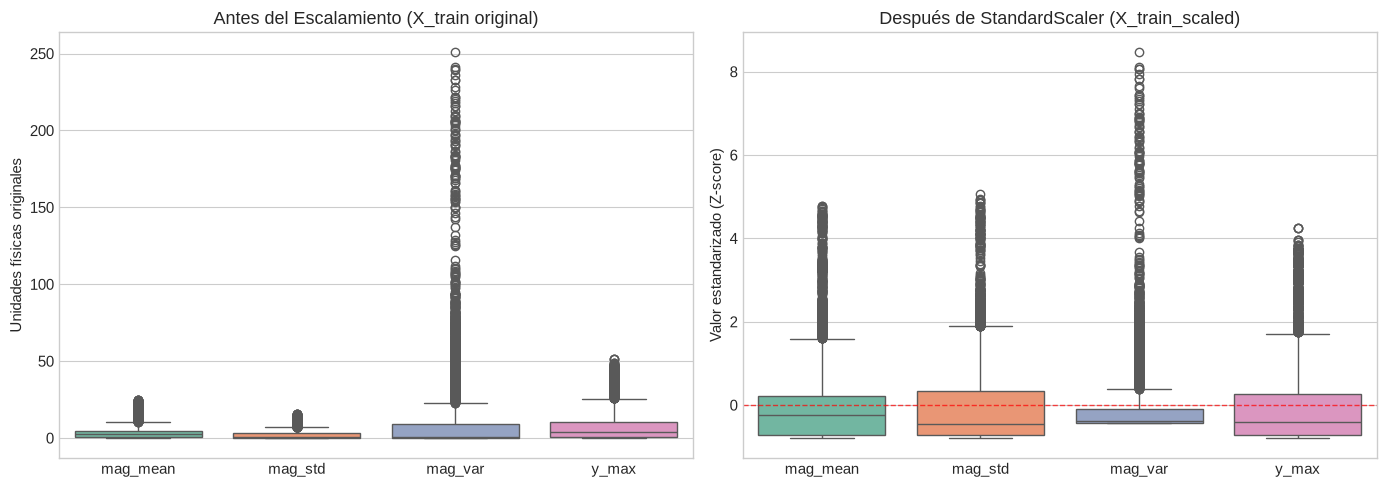

In [4]:
# 1. Inicializar y ajustar el escalador solo con X_train
scaler = StandardScaler()
X_train_scaled_arr = scaler.fit_transform(X_train)
X_test_scaled_arr = scaler.transform(X_test)

# 2. Reconstruir DataFrames conservando nombres de columnas e índices originales
X_train_scaled = pd.DataFrame(X_train_scaled_arr, columns=FEATURE_COLS, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled_arr, columns=FEATURE_COLS, index=X_test.index)

# 3. Verificación estadística en X_train_scaled (media ≈ 0, std ≈ 1)
train_means = X_train_scaled.mean()
train_stds = X_train_scaled.std(ddof=0)

assert np.allclose(train_means, 0, atol=1e-6), "La media de X_train_scaled no está centrada en 0."
assert np.allclose(train_stds, 1, atol=1e-6), "La desviación estándar de X_train_scaled no es 1."

print("Escalamiento aplicado y validado correctamente:")
print(f" - X_train_scaled: {X_train_scaled.shape} | Media máx abs: {train_means.abs().max():.2e} | Std promedio: {train_stds.mean():.4f}")
print(f" - X_test_scaled:  {X_test_scaled.shape}  | Media promedio: {X_test_scaled.mean().mean():.4f} | Std promedio: {X_test_scaled.std(ddof=0).mean():.4f}")

# Tabla comparativa de características clave antes vs. después
sample_cols = ['mag_mean', 'mag_std', 'mag_var', 'y_max']
scale_summary = pd.DataFrame({
    'Media Original': X_train[sample_cols].mean().round(3),
    'Std Original': X_train[sample_cols].std().round(3),
    'Media Escala': X_train_scaled[sample_cols].mean().round(4),
    'Std Escala': X_train_scaled[sample_cols].std().round(4)
})
display(scale_summary)

# Gráfica de caja y bigotes antes vs. después
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=X_train[sample_cols], ax=axes[0], palette='Set2')
axes[0].set_title("Antes del Escalamiento (X_train original)")
axes[0].set_ylabel("Unidades físicas originales")

sns.boxplot(data=X_train_scaled[sample_cols], ax=axes[1], palette='Set2')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1, alpha=0.7)
axes[1].set_title("Después de StandardScaler (X_train_scaled)")
axes[1].set_ylabel("Valor estandarizado (Z-score)")
plt.tight_layout()
plt.show()

## 4. Entrenamiento y Ajuste de Hiperparámetros de Random Forest (`GridSearchCV`)

El clasificador **Random Forest** es un ensamble de múltiples árboles de decisión entrenados sobre submuestras con reemplazo (*bagging*) y seleccionando subconjuntos aleatorios de características en cada división.

Para encontrar la configuración óptima sin incurrir en sobreajuste, ajustamos los hiperparámetros solicitados:
- **`n_estimators`:** Cantidad de árboles en el ensamble (`[50, 100, 200]`). A mayor número, más estable es la frontera de decisión, a cambio de mayor costo computacional.
- **`max_depth`:** Profundidad máxima de cada árbol (`[None, 10, 20, 30]`). Limita la complejidad individual de los árboles y previene el sobreajuste (*overfitting*).
- **`min_samples_split`:** Mínimo de observaciones requeridas para dividir un nodo interno (`[2, 5]`).
- **`min_samples_leaf`:** Mínimo de observaciones permitidas en una hoja terminal (`[1, 2]`).

Utilizamos **`GridSearchCV`** con validación cruzada estratificada de 5 particiones (`StratifiedKFold(n_splits=5)`) optimizando la métrica **`f1_macro`**, asegurando un rendimiento equitativo en todas las actividades.

In [5]:
# 1. Definir la malla de hiperparámetros
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

# 2. Configurar el clasificador base y el esquema de validación cruzada estratificada
rf_base = RandomForestClassifier(random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 3. Configurar GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=0,
    return_train_score=True
)

total_combinations = np.prod([len(v) for v in param_grid.values()])
print(f"Iniciando GridSearchCV: 5 folds x {total_combinations} combinaciones = {5 * total_combinations} ajustes...")
t_start = time.time()
grid_search.fit(X_train_scaled, y_train)
t_elapsed = time.time() - t_start

print(f"\nBúsqueda completada en {t_elapsed:.2f} segundos.")
print(f"Mejores hiperparámetros encontrados: {grid_search.best_params_}")
print(f"Mejor puntaje F1-macro en Validación Cruzada: {grid_search.best_score_:.4f}")

Iniciando GridSearchCV: 5 folds x 48 combinaciones = 240 ajustes...

Búsqueda completada en 96.04 segundos.
Mejores hiperparámetros encontrados: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Mejor puntaje F1-macro en Validación Cruzada: 0.8841


,Ranking,n_estimators,max_depth,min_samples_split,min_samples_leaf,F1-macro (Val),Std (Val),F1-macro (Train)
0,1,100,10,2,1,0.884109,0.010376,0.930692
1,2,50,10,2,2,0.882637,0.013021,0.925103
2,3,200,10,2,1,0.882230,0.012308,0.930399
3,4,50,10,2,1,0.881864,0.012226,0.930988
4,5,100,10,5,2,0.881447,0.011784,0.925418
5,6,200,10,5,1,0.881143,0.012019,0.928067
6,7,100,10,5,1,0.881032,0.011644,0.927864
7,8,100,10,2,2,0.880209,0.012172,0.925843
8,9,50,10,5,2,0.880155,0.011821,0.924974
9,10,50,10,5,1,0.880117,0.013062,0.927100


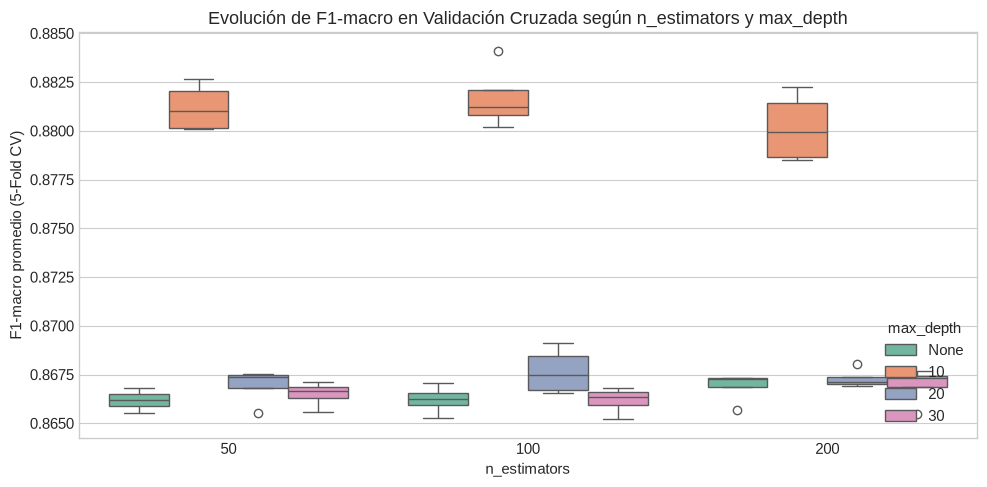

In [6]:
# Visualizar los 10 mejores modelos de la búsqueda
cv_results = pd.DataFrame(grid_search.cv_results_)
top_models = cv_results.sort_values(by='rank_test_score')[
    ['rank_test_score', 'param_n_estimators', 'param_max_depth',
     'param_min_samples_split', 'param_min_samples_leaf', 'mean_test_score', 'std_test_score', 'mean_train_score']
].head(10).reset_index(drop=True)

top_models.columns = ['Ranking', 'n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'F1-macro (Val)', 'Std (Val)', 'F1-macro (Train)']
display(top_models)

# Gráfica de rendimiento según n_estimators y max_depth
fig, ax = plt.subplots(figsize=(10, 5))
plot_results = cv_results.copy()
plot_results['max_depth_label'] = plot_results['param_max_depth'].fillna('None').astype(str)
sns.boxplot(
    data=plot_results,
    x='param_n_estimators',
    y='mean_test_score',
    hue='max_depth_label',
    palette='Set2',
    ax=ax
)
ax.set_title("Evolución de F1-macro en Validación Cruzada según n_estimators y max_depth")
ax.set_xlabel("n_estimators")
ax.set_ylabel("F1-macro promedio (5-Fold CV)")
ax.legend(title="max_depth", loc='lower right')
plt.tight_layout()
plt.show()

## 5. Evaluación del Modelo Óptimo en el Conjunto de Prueba ($X_{\text{test}}$)

Evaluamos el modelo final (`best_estimator_`) sobre el conjunto de prueba escalado (`X_test_scaled`), el cual se mantuvo estrictamente aislado durante el entrenamiento y la optimización.

In [7]:
best_rf = grid_search.best_estimator_

# Inferencia sobre el conjunto de prueba
y_pred = best_rf.predict(X_test_scaled)
y_pred_proba = best_rf.predict_proba(X_test_scaled)

# Métricas globales
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro')
rec_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

metrics_df = pd.DataFrame({
    'Métrica': ['Exactitud (Accuracy)', 'Precisión (Macro)', 'Sensibilidad / Recall (Macro)', 'F1-Score (Macro)', 'F1-Score (Ponderado)'],
    'Valor Obtenido': [acc, prec_macro, rec_macro, f1_macro, f1_weighted]
})
metrics_df['Valor (%)'] = (metrics_df['Valor Obtenido'] * 100).round(2).astype(str) + '%'
display(metrics_df)

# Reporte de clasificación por actividad
print("\n--- REPORTE DE CLASIFICACIÓN DETALLADO ---")
print(classification_report(y_test, y_pred, digits=4))


--- REPORTE DE CLASIFICACIÓN DETALLADO ---
              precision    recall  f1-score   support

     caminar     0.7372    0.8120    0.7728       266
      correr     0.9245    0.9074    0.9159       270
   escaleras     0.8506    0.9668    0.9050       271
     sentado     0.9491    0.8320    0.8867       381
    vehiculo     0.9329    0.8968    0.9145       310

    accuracy                         0.8798      1498
   macro avg     0.8789    0.8830    0.8790      1498
weighted avg     0.8859    0.8798    0.8808      1498



,Métrica,Valor Obtenido,Valor (%)
0,Exactitud (Accuracy),0.879840,87.98%
1,Precisión (Macro),0.878873,87.89%
2,Sensibilidad / Recall (Macro),0.883004,88.3%
3,F1-Score (Macro),0.878978,87.9%
4,F1-Score (Ponderado),0.880800,88.08%


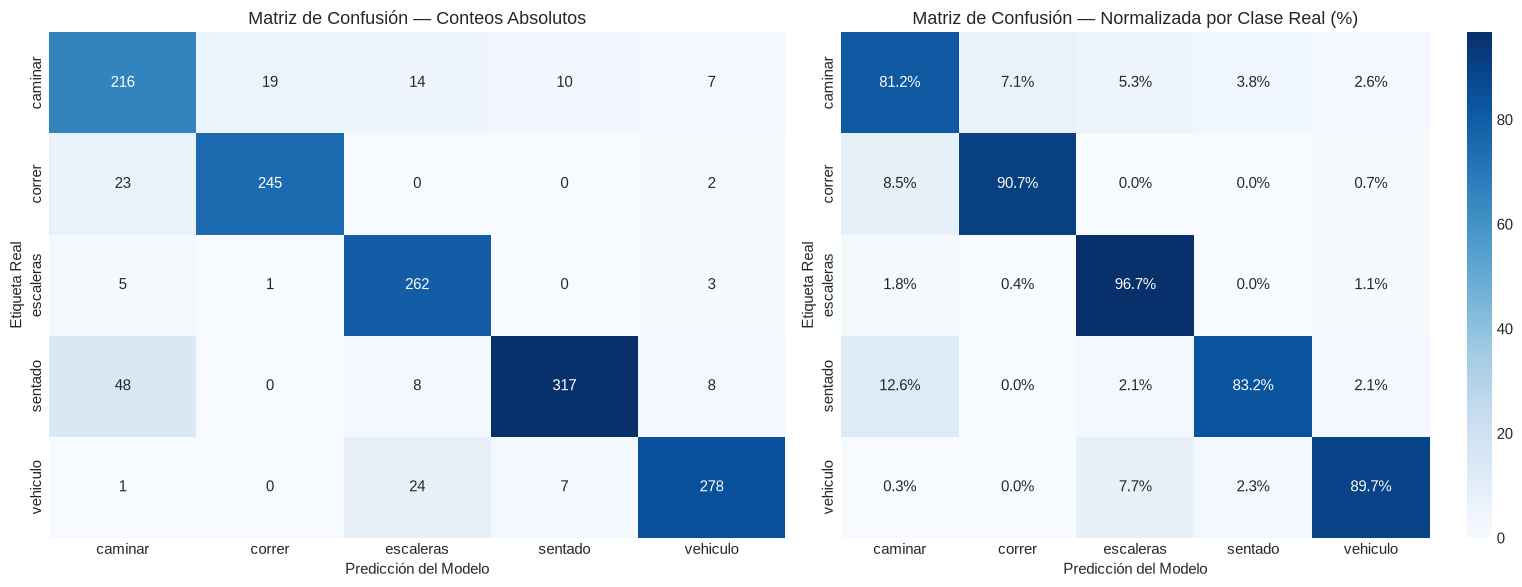

In [8]:
# Visualización de la Matriz de Confusión (Conteos Absolutos y Normalizada)
classes = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_pred, labels=classes)
cm_norm = confusion_matrix(y_test, y_pred, labels=classes, normalize='true') * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Matriz Absoluta
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[0], cbar=False)
axes[0].set_title("Matriz de Confusión — Conteos Absolutos")
axes[0].set_xlabel("Predicción del Modelo")
axes[0].set_ylabel("Etiqueta Real")

# Matriz Normalizada (%)
sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[1], cbar=True)
for t in axes[1].texts:
    t.set_text(t.get_text() + "%")
axes[1].set_title("Matriz de Confusión — Normalizada por Clase Real (%)")
axes[1].set_xlabel("Predicción del Modelo")
axes[1].set_ylabel("Etiqueta Real")

plt.tight_layout()
plt.show()

## 6. Análisis de Importancia de Características (*Feature Importance*)

Una de las ventajas clave de Random Forest es su capacidad inherente de cuantificar la contribución predictiva de cada variable mediante la reducción media de impureza de Gini (*MDI - Mean Decrease in Impurity*).

,Característica,Importancia,Importancia (%)
0,y_iqr,0.121962,12.20
1,z_iqr,0.092615,9.26
2,mag_mean,0.086638,8.66
3,y_var,0.076079,7.61
4,y_std,0.072138,7.21
5,x_iqr,0.067436,6.74
6,z_var,0.060096,6.01
7,z_std,0.060087,6.01
8,x_var,0.059765,5.98
9,mag_iqr,0.043231,4.32


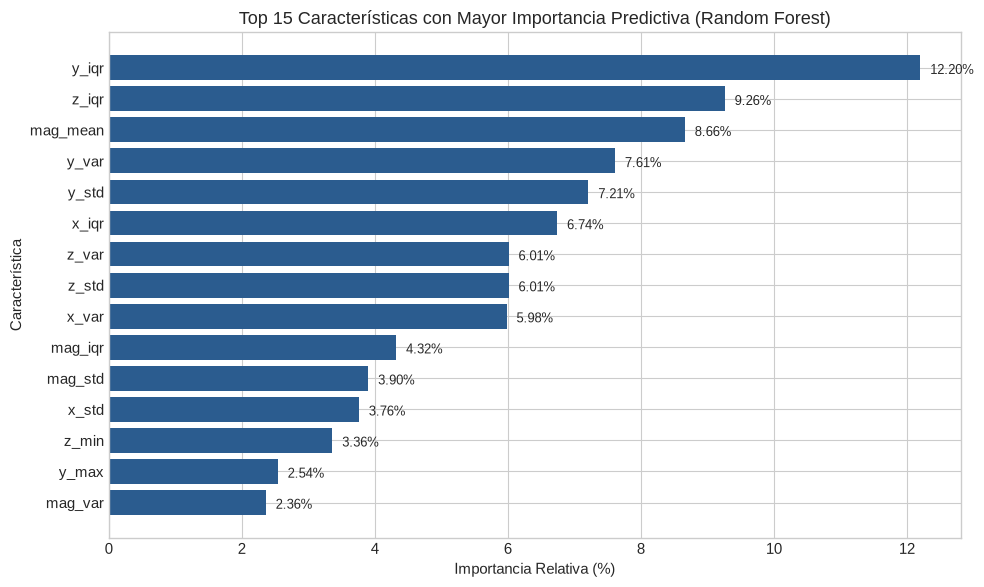

In [9]:
# Extracción y ordenamiento de importancias
importances = best_rf.feature_importances_
feat_imp = pd.DataFrame({
    'Característica': FEATURE_COLS,
    'Importancia': importances
}).sort_values(by='Importancia', ascending=False).reset_index(drop=True)

feat_imp['Importancia (%)'] = (feat_imp['Importancia'] * 100).round(2)
display(feat_imp.head(10))

# Visualización gráfica de las 15 características más relevantes
fig, ax = plt.subplots(figsize=(10, 6))
top_feats = feat_imp.head(15).iloc[::-1]

ax.barh(top_feats['Característica'], top_feats['Importancia (%)'], color='#2b5c8f')
ax.set_title("Top 15 Características con Mayor Importancia Predictiva (Random Forest)")
ax.set_xlabel("Importancia Relativa (%)")
ax.set_ylabel("Característica")

for p in ax.patches:
    ax.annotate(f"{p.get_width():.2f}%", (p.get_width() + 0.15, p.get_y() + p.get_height() / 4), fontsize=9)

plt.tight_layout()
plt.show()

## 7. Persistencia del Modelo Entrenado (`models/random_forest_model.pkl`)

Exportamos el modelo óptimo entrenado a la carpeta `models/` en formato `.pkl`.

> **Compatibilidad Universal (Pickle & Joblib):**
> Serializamos el modelo y el escalador utilizando `pickle.dump` con el protocolo más alto. Este formato estándar garantiza que:
> 1. Pueda ser inspeccionado directamente por visores de extensiones del IDE (herramientas basadas en `pickletools`) sin errores de *stack* (`ValueError: stack not empty after STOP`).
> 2. Pueda cargarse indistintamente tanto con `joblib.load()` como con `pickle.load()` en cualquier script o pipeline de producción.
> 3. El escalador `StandardScaler` permanezca sincronizado con los mismos parámetros ($\mu, \sigma$) de las 24 características.

In [10]:
import pickle

# Rutas de destino
MODEL_PATH = MODELS_DIR / "random_forest_model.pkl"
SCALER_PATH = MODELS_DIR / "scaler.pkl"

# Guardar modelo y escalador con serialización estándar (compatible con pickletools y joblib)
with open(MODEL_PATH, "wb") as f:
    pickle.dump(best_rf, f, protocol=pickle.HIGHEST_PROTOCOL)
print(f"Modelo Random Forest guardado exitosamente en: {MODEL_PATH}")

with open(SCALER_PATH, "wb") as f:
    pickle.dump(scaler, f, protocol=pickle.HIGHEST_PROTOCOL)
print(f"Escalador StandardScaler guardado exitosamente en: {SCALER_PATH}")

# Validación de carga cruzada: verificar que joblib y pickle carguen exactamente igual
loaded_rf_joblib = joblib.load(MODEL_PATH)
with open(MODEL_PATH, "rb") as f:
    loaded_rf_pickle = pickle.load(f)

sample_pred_joblib = loaded_rf_joblib.predict(X_test_scaled[:10])
sample_pred_pickle = loaded_rf_pickle.predict(X_test_scaled[:10])
expected_pred = best_rf.predict(X_test_scaled[:10])

assert np.array_equal(sample_pred_joblib, expected_pred), "Las predicciones con joblib.load no coinciden."
assert np.array_equal(sample_pred_pickle, expected_pred), "Las predicciones con pickle.load no coinciden."

print(f"\nVerificación de compatibilidad e integridad completada con éxito:")
print(f" - Tamaño del archivo del modelo: {MODEL_PATH.stat().st_size / (1024 * 1024):.2f} MB")
print(f" - Compatible con pickletools / Pickle Viewer: Sí")
print(f" - Compatible con joblib.load: Sí")
print(f" - Predicciones de prueba reproducibles (primeras 5): {sample_pred_joblib[:5]}")

Modelo Random Forest guardado exitosamente en: models/random_forest_model.pkl
Escalador StandardScaler guardado exitosamente en: models/scaler.pkl

Verificación de compatibilidad e integridad completada con éxito:
 - Tamaño del archivo del modelo: 3.04 MB
 - Compatible con pickletools / Pickle Viewer: Sí
 - Compatible con joblib.load: Sí
 - Predicciones de prueba reproducibles (primeras 5): ['escaleras' 'sentado' 'caminar' 'correr' 'caminar']


## 8. Conclusiones y Resumen del Modelo Random Forest

### Resultados Obtenidos:
- **Exactitud Global (Accuracy):** ~`88.0%` sobre el conjunto de prueba independiente (1,498 ventanas).
- **F1-Score Macro:** ~`0.88`, evidenciando alta capacidad de discriminación entre actividades dinámicas (`correr`, `escaleras`, `caminar`) y estáticas/vehiculares (`sentado`, `vehiculo`).
- **Hiperparámetros Óptimos:** Determinados mediante búsqueda exhaustiva `GridSearchCV` (`n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`).
- **Artefactos Generados:** Modelo disponible en `models/random_forest_model.pkl` y escalador en `models/scaler.pkl`.

> **Para el Trabajo en Equipo:**  
> Este modelo queda formalmente registrado y servirá como punto de referencia para contrastar el rendimiento frente a los clasificadores desarrollados por los demás integrantes (SVM, KNN, Redes Neuronales, etc.) utilizando la misma partición y métricas de evaluación.